<a href="https://colab.research.google.com/github/arikelasumanjali-coder/DL/blob/main/Skill_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("VISIONPORT - SKILL 3")
print("Complete Inference Pipeline")
print("--------------------------------")
print("1. Request Validation")
print("2. Image Decoding")
print("3. Resizing and Letterboxing")
print("4. Tensor Preparation")
print("5. Model Invocation")
print("6. Postprocessing")
print("7. Response Serialization")
print("--------------------------------")
print("Environment initialized!")

VISIONPORT - SKILL 3
Complete Inference Pipeline
--------------------------------
1. Request Validation
2. Image Decoding
3. Resizing and Letterboxing
4. Tensor Preparation
5. Model Invocation
6. Postprocessing
7. Response Serialization
--------------------------------
Environment initialized!


In [2]:
!pip install -q fastapi uvicorn python-multipart opencv-python-headless onnxruntime

In [3]:
import cv2
import numpy as np
import fastapi
import onnxruntime as ort

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("FastAPI:", fastapi.__version__)
print("ONNX Runtime:", ort.__version__)

print("\nAvailable ONNX providers:")
print(ort.get_available_providers())

print("\nAll dependencies verified successfully!")

OpenCV: 5.0.0
NumPy: 2.4.6
FastAPI: 0.141.1
ONNX Runtime: 1.31.1

Available ONNX providers:
['AzureExecutionProvider', 'CPUExecutionProvider']

All dependencies verified successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
image_bytes = uploaded[filename]

print("Uploaded file:", filename)
print("File size:", len(image_bytes), "bytes")

Saving traffic_image.jpg to traffic_image.jpg
Uploaded file: traffic_image.jpg
File size: 8373 bytes


In [5]:
import cv2
import numpy as np

def validate_and_decode(filename, image_bytes):

    allowed_extensions = (".jpg", ".jpeg", ".png")

    # Request validation
    if not filename.lower().endswith(allowed_extensions):
        raise ValueError("Invalid file format")

    if len(image_bytes) == 0:
        raise ValueError("Empty image uploaded")

    # Image decoding
    image_array = np.frombuffer(image_bytes, np.uint8)
    image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

    if image is None:
        raise ValueError("Image decoding failed")

    return image


image = validate_and_decode(filename, image_bytes)

print("Request validation: PASSED")
print("Image decoding: PASSED")
print("Image dimensions:", image.shape)
print("Image successfully decoded!")

Request validation: PASSED
Image decoding: PASSED
Image dimensions: (148, 251, 3)
Image successfully decoded!


In [6]:
def letterbox(image, new_size=640, color=(114, 114, 114)):

    h, w = image.shape[:2]

    # Calculate scaling ratio
    scale = min(new_size / w, new_size / h)

    new_w = int(round(w * scale))
    new_h = int(round(h * scale))

    # Resize image
    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR
    )

    # Calculate padding
    pad_w = new_size - new_w
    pad_h = new_size - new_h

    left = pad_w // 2
    right = pad_w - left
    top = pad_h // 2
    bottom = pad_h - top

    # Add padding
    output = cv2.copyMakeBorder(
        resized,
        top, bottom, left, right,
        cv2.BORDER_CONSTANT,
        value=color
    )

    return output, scale, left, top


letterboxed, scale, pad_x, pad_y = letterbox(image)

print("Original shape:", image.shape)
print("Letterboxed shape:", letterboxed.shape)
print("Scaling ratio:", scale)
print("Padding X:", pad_x)
print("Padding Y:", pad_y)

Original shape: (148, 251, 3)
Letterboxed shape: (640, 640, 3)
Scaling ratio: 2.549800796812749
Padding X: 0
Padding Y: 131


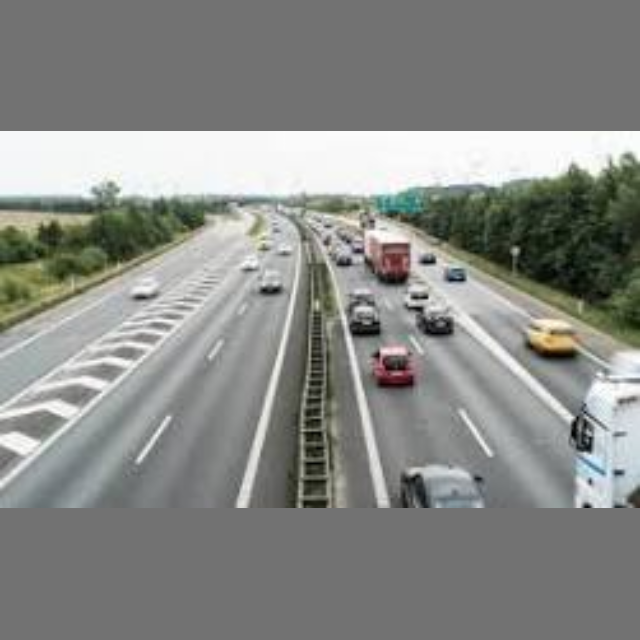

In [9]:
from google.colab.patches import cv2_imshow

cv2_imshow(letterboxed)

In [10]:
# Convert BGR to RGB
rgb_image = cv2.cvtColor(letterboxed, cv2.COLOR_BGR2RGB)

# Normalize pixel values
normalized = rgb_image.astype(np.float32) / 255.0

# Convert HWC to CHW
chw_image = np.transpose(normalized, (2, 0, 1))

# Add batch dimension
input_tensor = np.expand_dims(chw_image, axis=0)

print("Tensor shape:", input_tensor.shape)
print("Tensor data type:", input_tensor.dtype)
print("Minimum value:", input_tensor.min())
print("Maximum value:", input_tensor.max())
print("Tensor preparation: PASSED")

Tensor shape: (1, 3, 640, 640)
Tensor data type: float32
Minimum value: 0.0
Maximum value: 1.0
Tensor preparation: PASSED


In [13]:
!pip install -q ultralytics

In [14]:
from ultralytics import YOLO

# Load pretrained YOLOv8 nano model
model = YOLO("yolov8n.pt")

# Export to ONNX
onnx_path = model.export(
    format="onnx",
    imgsz=640,
    opset=17,
    simplify=False,
    dynamic=False
)

print("ONNX MODEL EXPORTED SUCCESSFULLY!")
print("Model location:", onnx_path)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

PyTorch: starting from 'yolov8n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 5 packages in 391ms
Prepared 1 package in 564ms
Installed 1 package in 34ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 1.3s

In [15]:
import os

print("Model exists:", os.path.exists(str(onnx_path)))
print("Model size:", round(os.path.getsize(str(onnx_path)) / (1024 * 1024), 2), "MB")

Model exists: True
Model size: 12.23 MB


In [16]:
import onnxruntime as ort

session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

print("YOLO MODEL LOADED SUCCESSFULLY")

input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

print("Input name:", input_name)
print("Input shape:", session.get_inputs()[0].shape)
print("Output name:", output_name)
print("Output shape:", session.get_outputs()[0].shape)

YOLO MODEL LOADED SUCCESSFULLY
Input name: images
Input shape: [1, 3, 640, 640]
Output name: output0
Output shape: [1, 84, 8400]


In [17]:
import time

start_time = time.time()

outputs = session.run(
    None,
    {input_name: input_tensor}
)

end_time = time.time()

print("MODEL INVOCATION: SUCCESS")
print("Number of outputs:", len(outputs))

for i, output in enumerate(outputs):
    print(f"Output {i} shape:", output.shape)
    print(f"Output {i} data type:", output.dtype)

print("Inference time:", round((end_time - start_time) * 1000, 2), "ms")

MODEL INVOCATION: SUCCESS
Number of outputs: 1
Output 0 shape: (1, 84, 8400)
Output 0 data type: float32
Inference time: 204.9 ms


In [18]:
# Extract model predictions
predictions = outputs[0][0].T

# Separate bounding boxes and class scores
boxes = predictions[:, :4]
class_scores = predictions[:, 4:]

# Find highest scoring class for each prediction
class_ids = np.argmax(class_scores, axis=1)
confidences = np.max(class_scores, axis=1)

# Confidence threshold
CONF_THRESHOLD = 0.25
NMS_THRESHOLD = 0.45

# Filter low-confidence predictions
mask = confidences >= CONF_THRESHOLD

boxes = boxes[mask]
class_ids = class_ids[mask]
confidences = confidences[mask]

print("Total predictions:", predictions.shape[0])
print("Predictions after confidence filtering:", len(boxes))

Total predictions: 8400
Predictions after confidence filtering: 78


In [19]:
# Convert YOLO center-based boxes to original image coordinates
detections = []

h, w = image.shape[:2]

for box, class_id, confidence in zip(boxes, class_ids, confidences):

    cx, cy, bw, bh = box

    x1 = int((cx - bw / 2 - pad_x) / scale)
    y1 = int((cy - bh / 2 - pad_y) / scale)
    x2 = int((cx + bw / 2 - pad_x) / scale)
    y2 = int((cy + bh / 2 - pad_y) / scale)

    # Clip coordinates to original image boundaries
    x1 = max(0, min(x1, w))
    y1 = max(0, min(y1, h))
    x2 = max(0, min(x2, w))
    y2 = max(0, min(y2, h))

    if x2 <= x1 or y2 <= y1:
        continue

    detections.append({
        "box": [x1, y1, x2 - x1, y2 - y1],
        "class_id": int(class_id),
        "confidence": float(confidence)
    })


# Apply class-wise Non-Maximum Suppression
final_detections = []

for class_id in set(d["class_id"] for d in detections):

    class_dets = [
        d for d in detections
        if d["class_id"] == class_id
    ]

    indices = cv2.dnn.NMSBoxes(
        [d["box"] for d in class_dets],
        [d["confidence"] for d in class_dets],
        CONF_THRESHOLD,
        NMS_THRESHOLD
    )

    for idx in np.array(indices).flatten():
        final_detections.append(class_dets[int(idx)])


final_detections.sort(
    key=lambda d: d["confidence"],
    reverse=True
)

print("Postprocessing completed!")
print("Final detections:", len(final_detections))


Postprocessing completed!
Final detections: 12


In [20]:
import json

response = {
    "status": "success",
    "model": "visionport_yolov8n_onnx",
    "image_size": {
        "width": int(image.shape[1]),
        "height": int(image.shape[0])
    },
    "inference_latency_ms": round(
        (end_time - start_time) * 1000, 2
    ),
    "total_detections": len(final_detections),
    "detections": [
        {
            "class_id": det["class_id"],
            "class_name": model.names[det["class_id"]],
            "confidence": round(det["confidence"], 4),
            "bounding_box": {
                "x": det["box"][0],
                "y": det["box"][1],
                "width": det["box"][2],
                "height": det["box"][3]
            }
        }
        for det in final_detections
    ]
}

json_response = json.dumps(response, indent=4)

print("FINAL API RESPONSE:")
print(json_response)

FINAL API RESPONSE:
{
    "status": "success",
    "model": "visionport_yolov8n_onnx",
    "image_size": {
        "width": 251,
        "height": 148
    },
    "inference_latency_ms": 204.9,
    "total_detections": 12,
    "detections": [
        {
            "class_id": 5,
            "class_name": "bus",
            "confidence": 0.7627,
            "bounding_box": {
                "x": 142,
                "y": 38,
                "width": 19,
                "height": 21
            }
        },
        {
            "class_id": 2,
            "class_name": "car",
            "confidence": 0.6903,
            "bounding_box": {
                "x": 206,
                "y": 73,
                "width": 22,
                "height": 16
            }
        },
        {
            "class_id": 2,
            "class_name": "car",
            "confidence": 0.664,
            "bounding_box": {
                "x": 136,
                "y": 67,
                "width": 13,
          